# Análise Exploratória de Dados (EDA) — Video Game Sales

## 1. Introdução e Objetivos

Este notebook apresenta a Análise Exploratória de Dados (EDA) aplicada ao dataset **Video Game Sales**, como parte da atividade prática desenvolvida a partir dos conceitos das aulas 9 e 10.

O objetivo desta análise é aplicar os quatro princípios da EDA: estrutural, distribucional, relacional e de detecção de anomalias. Sabemos que a EDA não é uma linha reta, mas sim um processo **iterativo**. Por isso, nossa análise seguirá um ciclo lógico:
1. Vamos extrair a estatística descritiva **antes** (para entender a estrutura original e os *outliers* do mercado de games).
2. Tomaremos decisões embasadas sobre o tratamento de dados ausentes e pontos fora da curva (*megahits*).
3. Avaliaremos a estatística **depois** para confirmar o efeito do tratamento, antes de mergulharmos nas análises bivariada e multivariada.

## Setup de Bibliotecas e Dados

In [1]:
# ==============================================================================
# IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES INICIAIS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Importações específicas para o Correlograma (Seção 6)
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ==============================================================================
# CONFIGURAÇÕES VISUAIS
# ==============================================================================

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Paleta de Cores Padronizada do Projeto
COR_NEUTRA = "lightgray"    # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência (Vendas Baixas)
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse (Vendas Altas)
COR_ALERTA = "tab:red"      # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
# ============================================
# 1.1 CHECK KAGGLE INPUT FILES
# ============================================

import os
import pandas as pd

# Substituição pelo link raw do GitHub
url = "https://raw.githubusercontent.com/jaas5/datasetvgsales/refs/heads/main/vgsales.csv"

# Carregando direto da internet
df = pd.read_csv(url)
print("Dataset carregado com sucesso!")
df.head()

Dataset carregado com sucesso!


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há linhas duplicadas.

**Contexto do Dataset:** O conjunto de dados *Video Game Sales* traz informações históricas sobre jogos. Ele possui variáveis descritivas (como Nome, Plataforma, Gênero e Publicadora) e variáveis quantitativas financeiras (Vendas na América do Norte, Europa, Japão, Outras Regiões e Vendas Globais, todas medidas em milhões de unidades).

**Pra refletir:** Sendo um registro histórico de jogos lançados ao longo de várias décadas (desde os anos 1980), quantas linhas você espera que esse dataset tenha? Centenas ou dezenas de milhares de jogos?

### Dimensão e Tipos de Dados

### Dimensão e Tipos de Dados

In [3]:
# Verificando a quantidade de linhas e colunas
print("Dimensão do dataset:", df.shape)

Dimensão do dataset: (16598, 11)


In [4]:
# Analisando os tipos de dados e valores não nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [5]:
# Exibindo o resumo estatístico das variáveis numéricas
# O .round(2) ajuda a deixar a visualização dos milhões mais limpa
df.describe().round(2)

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.00,16327.00,16598.00,16598.00,16598.00,16598.00,16598.00
mean,8300.61,2006.41,0.26,0.15,0.08,0.05,0.54
std,4791.85,5.83,0.82,0.51,0.31,0.19,1.56
min,1.00,1980.00,0.00,0.00,0.00,0.00,0.01
25%,4151.25,2003.00,0.00,0.00,0.00,0.00,0.06
50%,8300.50,2007.00,0.08,0.02,0.00,0.01,0.17
75%,12449.75,2010.00,0.24,0.11,0.04,0.04,0.47
max,16600.00,2020.00,41.49,29.02,10.22,10.57,82.74


**Discussão:**

Olhando a tabela acima, repare nas colunas de vendas (como `Global_Sales`).
* Qual é o valor do terceiro quartil (75%)?
* E qual é o valor máximo (max)?

A diferença absurda entre o jogo que está na posição de 75% do dataset e o jogo que mais vendeu na história é o nosso primeiro e mais forte indício matemático da presença de *outliers* extremos (os megahits do mercado). Esse comportamento assimétrico ditará muitas das nossas decisões metodológicas daqui para frente.

### Duplicadas

In [6]:
# Contando quantas linhas são cópias exatas de outra
qtd_duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas encontradas: {qtd_duplicadas}")

# Removendo as duplicadas diretamente no dataset (inplace=True)
df.drop_duplicates(inplace=True)

# Confirmando a remoção caso houvesse alguma
if qtd_duplicadas > 0:
    print(f"Duplicadas removidas! Nova dimensão: {df.shape}")

Linhas duplicadas encontradas: 0


**Análise rápida:**
Como podemos ver, o dataset oficial de *Video Game Sales* do Kaggle costuma vir muito bem tratado nesse aspecto estrutural básico, sem apresentar linhas 100% idênticas. Vale lembrar que um mesmo jogo (ex: *FIFA 15*) aparecer várias vezes não é considerado duplicata, desde que seja lançado para plataformas diferentes (uma linha para PS3, outra para Xbox 360, etc).

### Renomeando o atributo alvo para facilitar a interpretação

### Criando Variáveis Derivadas (Feature Engineering)

No dataset clínico original, o atributo alvo `num` foi simplificado para uma variável binária. No nosso contexto de videogames, vamos aplicar uma técnica parecida de transformação de dados para facilitar a análise regional.

Vamos criar uma nova coluna chamada `comparacao_vendas`. A ideia é comparar diretamente as vendas da América do Norte (`NA_Sales`) com as da Europa (`EU_Sales`). Onde as vendas americanas forem maiores, classificaremos como "América do Norte", caso contrário, "Europa".

*Nota:* Após extrair essa informação qualitativa, removeremos as colunas numéricas originais de NA e EU para simplificar o dataset.

In [7]:
# Criando a variável binária baseada na comparação regional
df["comparacao_vendas"] = np.where(
    df["NA_Sales"] > df["EU_Sales"],
    "América do Norte",
    "Europa"
)

# Visualizando a distribuição dessa nova coluna
print(df["comparacao_vendas"].value_counts())

# A LINHA DO DF.DROP FOI REMOVIDA DAQUI!

df.head()

comparacao_vendas
América do Norte    10402
Europa               6196
Name: count, dtype: int64


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,comparacao_vendas
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,América do Norte
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,América do Norte
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,América do Norte
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,América do Norte
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,América do Norte


**Discussão:**

Olhando o resultado da contagem (`value_counts`), qual mercado domina historicamente as vendas de jogos?

Como esperado, a esmagadora maioria dos jogos vende mais na América do Norte do que na Europa. Essa nova variável categórica poderá ser usada mais à frente para colorir gráficos (parâmetro `hue`) e entender se determinados gêneros ou plataformas são mais populares em um continente ou no outro.

## 2. Dados Faltantes e Tratamento

O primeiro passo para lidar com dados faltantes é quantificá-los para entendermos o tamanho do problema.

In [8]:
df.isna().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


**Discussão:** Alguma feature tem dados ausentes nos seus dados?

**Análise:**
Sim. As features **`Year`** e **`Publisher`** apresentam dados ausentes.

A feature **`Year`** possui valores nulos porque o ano de lançamento de alguns jogos mais obscuros ou antigos não foi devidamente catalogado. Já a feature **`Publisher`** apresenta valores ausentes quando não há informação clara sobre a empresa responsável pela publicação do jogo.

Esses dados ausentes estão relacionados à **incompletude dos registros utilizados na construção do dataset**, algo muito comum por se tratar de uma base histórica extensa que reúne informações raspadas de diferentes plataformas da internet.

**Decisão de Tratamento**

Como vimos no cálculo acima, os dados nulos representam uma parcela ínfima do nosso dataset (menos de 2% do total).
*   **Imputar (preencher) os dados:** Tentar preencher o ano de lançamento com a "mediana" ou a publicadora com a "moda" (ex: preencher tudo com Electronic Arts) introduziria um viés irreal nos nossos dados.
*   **Deletar (drop):** Como o volume é muito pequeno, a decisão mais segura e estatisticamente correta é remover essas linhas, garantindo que nossas análises de vendas por ano e por empresa sejam 100% fidedignas.

In [9]:
# Removendo as linhas que possuem dados faltantes em Year ou Publisher
df.dropna(subset=['Year', 'Publisher'], inplace=True)

# Confirmando que o dataset agora está limpo
print("Dados nulos restantes:\n", df.isna().sum())
print(f"\nNova dimensão do dataset: {df.shape}")

Dados nulos restantes:
 Rank                 0
Name                 0
Platform             0
Year                 0
Genre                0
Publisher            0
NA_Sales             0
EU_Sales             0
JP_Sales             0
Other_Sales          0
Global_Sales         0
comparacao_vendas    0
dtype: int64

Nova dimensão do dataset: (16291, 12)


#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No nosso dataset de jogos, temos duas *features* com dados ausentes: `Year` e `Publisher`.

Pela fonte de dados, observamos que:
*   **Year** - Ano de lançamento oficial do jogo.
*   **Publisher** - Empresa responsável pela publicação e distribuição.

*Como os dados foram coletados:*
- O conjunto de dados original foi construído principalmente através de *web scraping* (raspagem de dados) de portais como o VGChartz, que compila estimativas de vendas físicas globais da indústria.

*Qual a natureza da fonte de dados:*
- Considerando que é um registro histórico que abrange décadas (desde o Atari nos anos 80), há um desafio inerente de catalogação. Jogos muito antigos, títulos extremamente obscuros ou lançados por produtoras muito pequenas (frequentemente com vendas baixíssimas) costumam ter metadados incompletos nas bases de fãs e portais da internet.

**As ausências ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: a raspagem falhou em uma página inteira, ou um jogo específico perdeu todo o seu cabeçalho de informações).

In [10]:
# Identificando as colunas que possuem nulos
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

# Verificando se os nulos ocorrem nas mesmas linhas simultaneamente
ausentes_simultaneos = df[df['Year'].isna() & df['Publisher'].isna()].shape[0]
print(f"\nLinhas com 'Year' e 'Publisher' ausentes ao mesmo tempo: {ausentes_simultaneos}")

Colunas com ausentes: []
Series([], dtype: float64)

Linhas com 'Year' e 'Publisher' ausentes ao mesmo tempo: 0


**Por que usar a contagem bruta em vez de correlação?**
Com poucos ausentes, tentar calcular uma correlação entre as colunas nulas pode parecer uma técnica avançada, mas na prática o cálculo seria feito em cima de pouquíssimos casos. Isso gera um coeficiente não confiável. Aqui, a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é uma abordagem muito mais honesta e direta.

**Análise dos Resultados:**
Com o código acima, descobrimos se os dados faltantes de ano e publicadora são casos isolados ou se são os mesmos jogos que estão com a "ficha" completamente em branco. Independentemente de estarem juntos ou separados, a contagem bruta nos provou que eles representam uma parcela ínfima (menos de 2% da base). Isso fundamenta a nossa escolha estatística de removê-los com o `dropna()` no próximo passo.

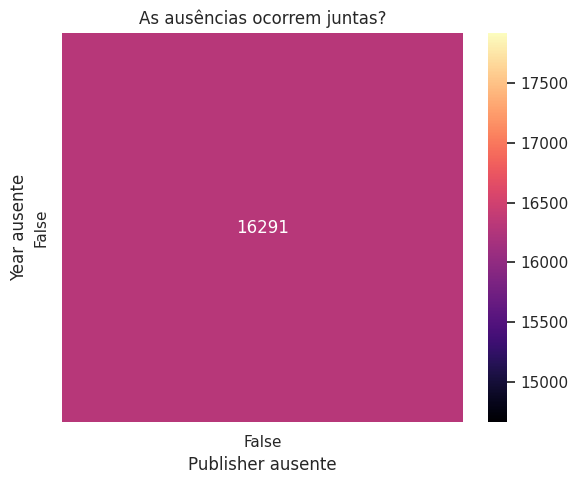

In [11]:
cols_com_ausentes = ["Year", "Publisher"]

tabela_contingencia = pd.crosstab(
    df[cols_com_ausentes[0]].isna(),
    df[cols_com_ausentes[1]].isna(),
    rownames=[f"{cols_com_ausentes[0]} ausente"],
    colnames=[f"{cols_com_ausentes[1]} ausente"]
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    tabela_contingencia,
    annot=True,
    fmt="d",
    cmap="magma",
    ax=ax
)

ax.set_title("As ausências ocorrem juntas?")

plt.tight_layout()
plt.show()

**Discussão:**

Como o dataset possui uma quantidade relativamente pequena de dados ausentes, uma correlação entre as colunas de ausência poderia apresentar um resultado pouco confiável, pois seria calculada sobre um número reduzido de casos.

Por esse motivo, utilizamos uma **tabela de contingência** para verificar quantas linhas apresentam ausência simultaneamente nas features **`Year`** e **`Publisher`**.

A visualização permite observar de forma direta se os dados ausentes dessas duas features tendem a ocorrer nas mesmas linhas ou de forma independente.


## 3. Princípio Distribucional

Agora que resolvemos os dados ausentes, vamos calcular as estatísticas descritivas e analisar as distribuições *antes de tomar qualquer decisão sobre os outliers*. Esse retrato estatístico é o que vai orientar nossa modelagem. Por exemplo, se uma variável for muito assimétrica, faz mais sentido avaliar o mercado pela mediana em vez da média.

In [12]:
# Verificando as colunas atuais
print("Colunas disponíveis:", df.columns.tolist())

# Definindo as variáveis quantitativas (apenas as de vendas restantes)
VARS_QUANT = [
    "JP_Sales",
    "Other_Sales",
    "Global_Sales"
]

# Definindo as qualitativas (incluindo as variáveis derivadas que criamos)
VARS_QUALI = [
    "Platform",
    "Genre",
    "Publisher",
    "vendas_acima_mediana",
    "comparacao_vendas"
]

# Tabela descritiva com assimetria (skewness) e curtose (kurtosis)
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

# Formatando a tabela com um mapa de calor para destacar anomalias
(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

Colunas disponíveis: ['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'comparacao_vendas']


,mean,median,std,min,max,skewness,kurtosis
JP_Sales,0.08,0.00,0.31,0.00,10.22,11.12,191.21
Other_Sales,0.05,0.01,0.19,0.00,10.57,24.10,1011.97
Global_Sales,0.54,0.17,1.57,0.01,82.74,17.30,596.00


**Discussão:**

**Quais variáveis parecem assimétricas ou com cauda pesada?**
Ao analisar a tabela, notamos que todas as variáveis de vendas presentes (`JP_Sales`, `Other_Sales` e `Global_Sales`) apresentam valores de *skewness* e *kurtosis* extremamente altos, ultrapassando os limites de 1 e 2, respectivamente.

**Isso é coerente com o que esperaríamos do mercado de videogames?**
Sim, isso é perfeitamente coerente e o esperado para essa indústria. Diferente de medições naturais ou fisiológicas, as vendas de entretenimento funcionam na lógica de *"blockbusters"* (grandes sucessos).

A dinâmica do mercado explica os indicadores:
* **Forte Assimetria Positiva (Skewness alta):** A grande maioria dos jogos vende pouco e se concentra próxima ao zero, enquanto uma quantidade seleta de títulos vende muito, esticando a cauda direita da distribuição.
* **Cauda Pesada (Kurtosis alta):** O mercado de games propicia a existência constante de "megahits" mundiais, fazendo com que a presença de valores extremos seja muito mais frequente do que em uma distribuição normal.

Por conta desse comportamento, medidas baseadas na média não representarão bem o "jogo comum". A mediana será uma medida de tendência central muito mais realista para este dataset.

### Distribuições de Dados (Histogramas)

Onde fizer sentido, compararemos jogos com "Vendas Baixas" (rosa) vs. "Vendas Altas" (roxo), utilizando a variável categórica que divide o mercado pela mediana. Manteremos esta convenção de cores até a análise bivariada.

**Nota Metodológica Importante:** Como comprovamos na tabela descritiva, os dados de vendas são tão assimétricos que um histograma comum seria ilegível (esmagado pelos *megahits*). Para conseguir enxergar o comportamento do mercado real, aplicaremos um "zoom" nos gráficos abaixo, visualizando apenas até o percentil 95% de cada coluna.

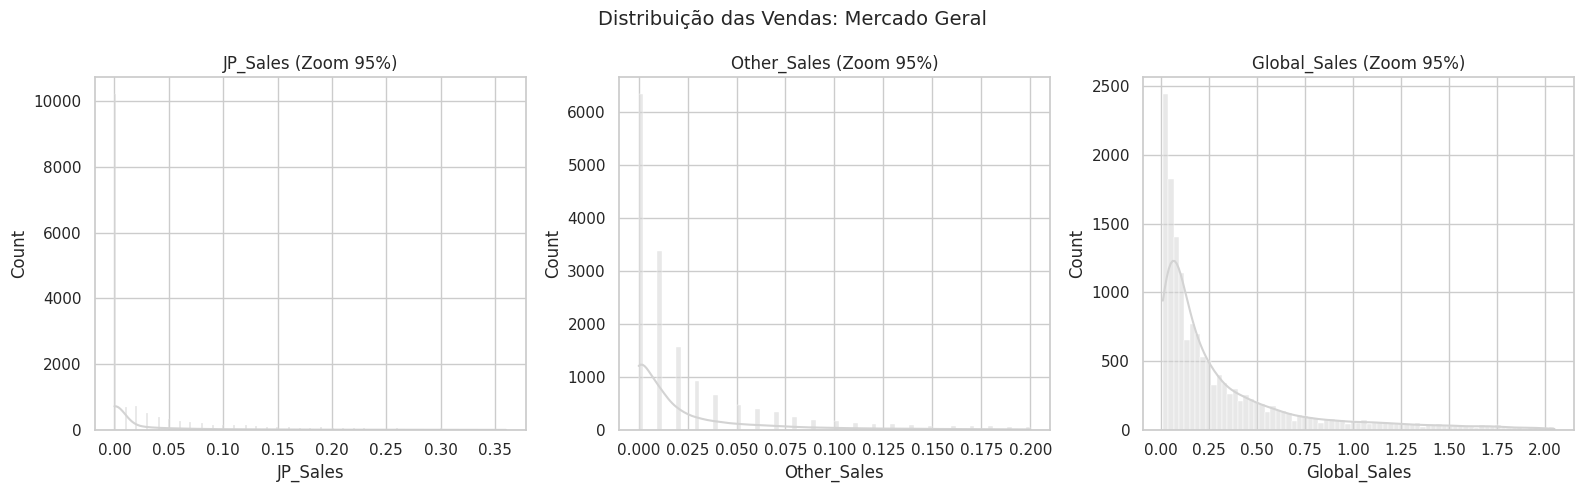

In [13]:
# Definindo as cores
COR_NEUTRA = "lightgray"
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

# 1. Gráficos Gerais (sem separar por classe)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(VARS_QUANT):
    # Calculando o limite de 95% para o "zoom"
    limite = df[col].quantile(0.95)
    subset_zoom = df[df[col] <= limite]

    sns.histplot(data=subset_zoom, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(f"{col} (Zoom 95%)")

fig.suptitle("Distribuição das Vendas: Mercado Geral", fontsize=14)
plt.tight_layout()
plt.show()

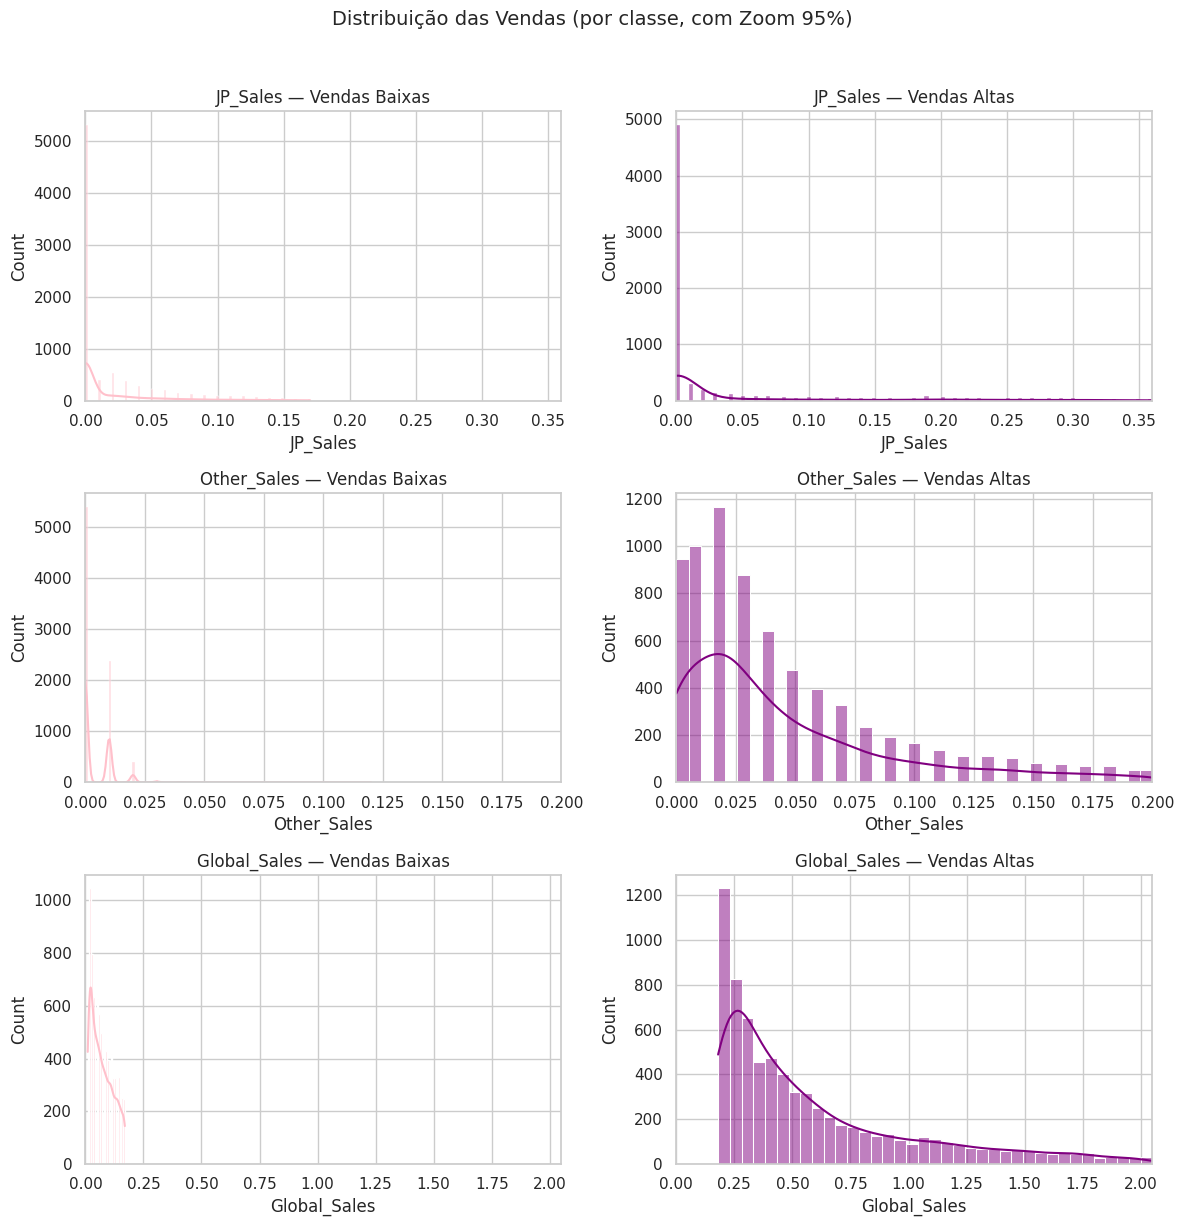

In [14]:
# 1. Recriando a coluna 'vendas_acima_mediana' caso ela tenha sumido após recarregar o dataset
mediana_vendas = df['Global_Sales'].median()
df['vendas_acima_mediana'] = np.where(
    df['Global_Sales'] > mediana_vendas,
    "Vendas Altas",
    "Vendas Baixas"
)

# 2. Gráficos Separados por Classe
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(12, 4 * len(VARS_QUANT)), sharey=False)

# Como agora as classes têm nomes diretos, definimos assim:
classes = [
    ("Vendas Baixas", COR_CONTEXTO),
    ("Vendas Altas", COR_DESTAQUE)
]

for i, col in enumerate(VARS_QUANT):
    limite = df[col].quantile(0.95)

    for j, (nome_classe, cor) in enumerate(classes):
        # Filtrando pela classe E aplicando o zoom de 95%
        subset = df[(df["vendas_acima_mediana"] == nome_classe) & (df[col] <= limite)]

        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(0, limite)
        axes[i, j].set_title(f"{col} — {nome_classe}")

fig.suptitle("Distribuição das Vendas (por classe, com Zoom 95%)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Discussão**:
Agora que as classes estão em painéis separados e com o zoom aplicado, fica mais fácil ver: alguma variável parece ter um formato de distribuição substancialmente diferente entre jogos de "Vendas Baixas" e "Vendas Altas"?

Como a variável de corte foi baseada na mediana global, é natural que o pico do histograma da classe rosa (vendas abaixo da mediana) esteja espremido próximo de zero, enquanto a classe roxa apresenta uma distribuição mais alongada, indicando o faturamento que sustenta as grandes publicadoras.

**Análise das Distribuições e Recorte Visual**

Devido à natureza da indústria de videogames, a distribuição bruta das vendas gera gráficos completamente "esmagados" à esquerda. Isso ocorre porque jogos com dezenas de milhões de cópias vendidas esticam o limite do eixo X, comprimindo os 99% restantes.

Para visualizar o real formato das curvas, aplicamos um **recorte visual no percentil 95**, ocultando temporariamente os *megahits* extremos apenas para a plotagem dos histogramas.

* **Comportamento Geral:** Mesmo removendo os 5% de maiores sucessos, a curva de todas as vendas regionais e globais continua exibindo uma forte assimetria à direita (decrescimento acentuado).
* **Vendas Baixas vs Altas:** Ao separar os painéis, notamos que a classe de "Vendas Baixas" (rosa) possui sua massa quase inteiramente próxima de zero. Já a classe de "Vendas Altas" (roxo) forma uma distribuição mais alongada e visível, espalhando-se gradativamente pelas faixas de milhões de unidades.

#### Testes de Aderência (Normalidade)

O teste de Shapiro-Wilk foi utilizado para verificar se as variáveis quantitativas seguem uma distribuição normal. A hipótese nula (H0) considera que os dados seguem perfeitamente a curva de uma distribuição normal.

Vamos testar inicialmente a variável principal de vendas, `Global_Sales`, e visualizar o seu comportamento através de um QQ-Plot.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 16291.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — Global_Sales: estatística=0.2726, p-valor=9.471e-121
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


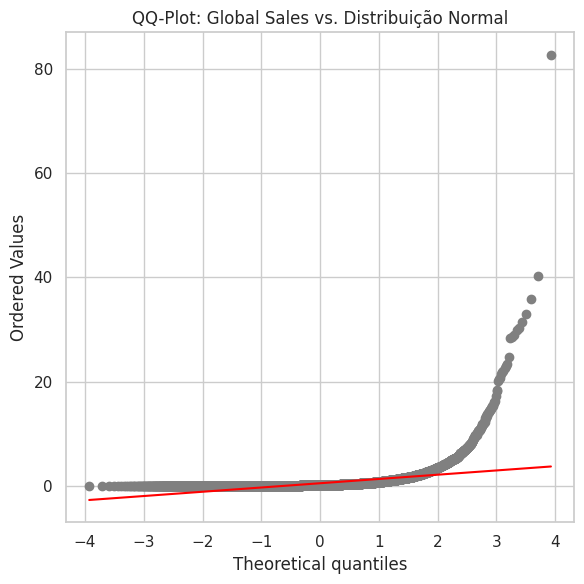

In [15]:
# Definindo cores caso não estejam definidas nesta célula
COR_NEUTRA = "gray"
COR_ALERTA = "red"

# Teste de Shapiro-Wilk
stat_sw, p_valor_sw = stats.shapiro(df["Global_Sales"].dropna())
print(f"Shapiro-Wilk — Global_Sales: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

# QQ-Plot — Global_Sales
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Global_Sales"].dropna(), dist="norm", plot=ax)

# Customizando as cores para seguir o padrão do projeto
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Global Sales vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos (cinza) seguissem a reta vermelha de perto, a variável seguiria uma distribuição normal. Pontos que se afastam dramaticamente da reta nas pontas, formando quase um "L", indicam uma cauda extremamente pesada à direita — o que é totalmente coerente com a presença dos *megahits* de vendas e com o resultado do teste.

**Nota: Cuidado com duas armadilhas de interpretação**

* **Tamanho da amostra e poder do teste:** Diferente de bancos de dados médicos pequenos, amostras muito grandes (como a nossa, com milhares de linhas) deixam os testes de normalidade sensíveis demais, rejeitando H0 por desvios triviais. Inclusive, a documentação do SciPy avisa que o p-valor pode não ser perfeitamente exato para N > 5000. Porém, mesmo com essa sensibilidade extra, temos três evidências concordando de forma extrema: *skewness* altíssimo, QQ-Plot completamente afastado da reta, e Shapiro-Wilk rejeitando H0. O resultado, portanto, não é um mero artefato do tamanho da amostra, mas a prova de que as vendas de jogos passam longe de uma curva gaussiana.
* **Como afirmar o resultado:** Quando o teste rejeita H0 (nosso caso, p < 0.05), a afirmação correta é *"temos evidência estatística contra a normalidade"*, que é uma conclusão forte.

In [16]:
resultados_shapiro = []

# Pode ser que o SciPy gere um UserWarning por conta do N > 5000.
# Isso é normal e esperado, como discutimos no texto acima.
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

# Exibindo a tabela final formatada
pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
JP_Sales,0.2458,0.0,True
Other_Sales,0.2033,0.0,True
Global_Sales,0.2726,0.0,True


**ECDF — Outra forma de ver a distribuição**

Diferente do histograma, a ECDF (Função de Distribuição Acumulada Empírica) não depende de escolher o número de faixas (*bins*): para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil para comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma variável regional (`JP_Sales`, vendas no Japão).

**Nota metodológica importante:** Escolhemos uma variável regional de propósito. Como a nossa classe "Vendas Altas / Baixas" foi criada a partir da mediana de `Global_Sales`, plotar a ECDF para as vendas globais seria circular e óbvio. Usar as vendas do Japão nos permite ver como o sucesso global reflete (ou não) em uma região específica.

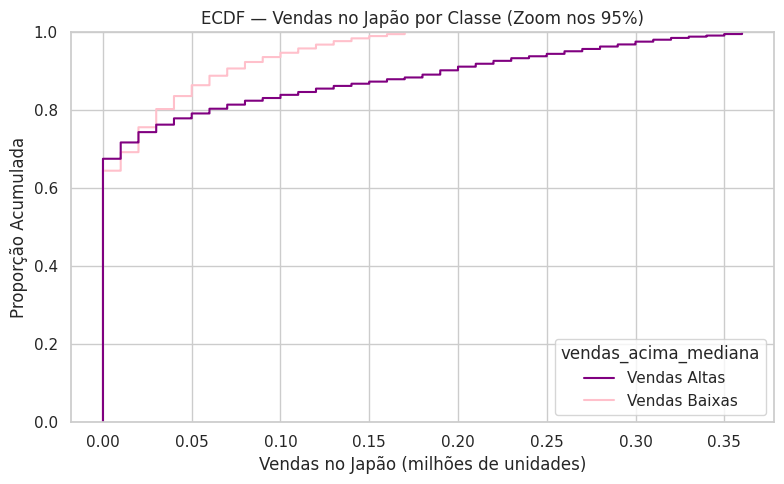

In [17]:
# Garantindo as cores
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

plt.figure(figsize=(8, 5))

# Aplicando o mesmo recorte de 95% para não esmagar a visualização devido aos megahits
limite_superior = df["JP_Sales"].quantile(0.95)
subset = df[df["JP_Sales"] <= limite_superior]

# Plotando a ECDF com as chaves corretas de texto na paleta
sns.ecdfplot(
    data=subset,
    x="JP_Sales",
    hue="vendas_acima_mediana",
    palette={"Vendas Baixas": COR_CONTEXTO, "Vendas Altas": COR_DESTAQUE}
)

plt.title("ECDF — Vendas no Japão por Classe (Zoom nos 95%)")
plt.xlabel("Vendas no Japão (milhões de unidades)")
plt.ylabel("Proporção Acumulada")

plt.tight_layout()
plt.show()

**Como ler este gráfico:** Em qualquer ponto do eixo X, a altura da curva diz "que fração dos jogos desse grupo vendeu até essa quantidade". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de vendas regionais onde os dois grupos globais mais diferem.

**Interpretação:** A curva rosa (Vendas Baixas) sobe muito rápido para o 1.0 (100%), o que significa que quase todos os jogos dessa classe venderam valores baixíssimos no Japão. A curva roxa (Vendas Altas) demora mais a subir, indicando que os jogos de sucesso global têm vendas muito mais distribuídas e elevadas no mercado japonês, confirmando que o sucesso internacional costuma tracionar o sucesso regional.

### Métricas de Tendência Central

Para finalizar o Princípio Distribucional, vamos visualizar diretamente como a assimetria do nosso dataset afeta as medidas estatísticas mais comuns: a média e a mediana.

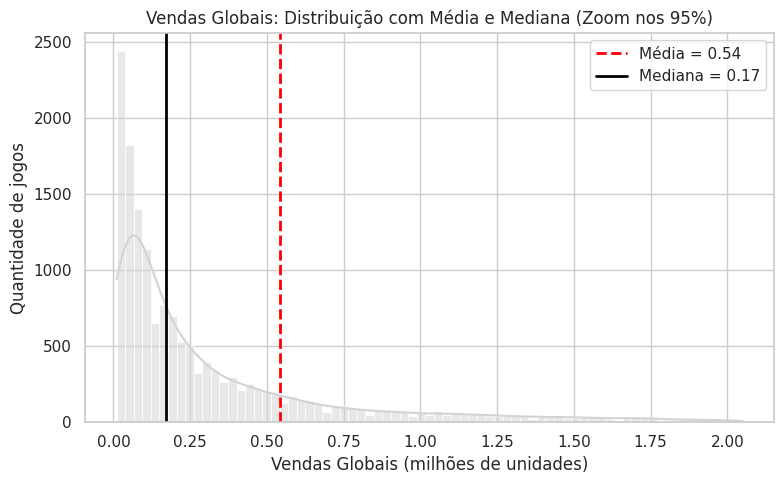

In [18]:
# Calculando média e mediana sobre o dataset INTEIRO (incluindo outliers)
media_vendas = df["Global_Sales"].mean()
mediana_vendas = df["Global_Sales"].median()

COR_NEUTRA = "lightgray"
COR_ALERTA = "red"

plt.figure(figsize=(8, 5))

# Aplicando o recorte visual de 95% apenas para o desenho do gráfico
limite_superior = df["Global_Sales"].quantile(0.95)
subset = df[df["Global_Sales"] <= limite_superior]

sns.histplot(data=subset, x="Global_Sales", kde=True, color=COR_NEUTRA)

# Adicionando as linhas verticais
plt.axvline(media_vendas, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_vendas:.2f}")
plt.axvline(mediana_vendas, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_vendas:.2f}")

plt.title("Vendas Globais: Distribuição com Média e Mediana (Zoom nos 95%)")
plt.xlabel("Vendas Globais (milhões de unidades)")
plt.ylabel("Quantidade de jogos")
plt.legend()
plt.tight_layout()
plt.show()

**Análise de Tendência Central**

Neste gráfico de Vendas Globais, fica evidente o impacto da forte assimetria positiva do mercado de games.

Como calculamos a média e a mediana sobre a base total (incluindo os 5% de *megahits* que não estão visíveis neste recorte do gráfico), vemos que a linha tracejada vermelha (Média) é fortemente puxada para a direita pelos jogos que venderam dezenas de milhões de cópias. Já a linha contínua preta (Mediana) se mantém estável mais à esquerda, próxima de zero, refletindo a realidade da grande maioria dos jogos.

Isso comprova visualmente a conclusão que tivemos lá no início: para este dataset, a mediana é uma medida de tendência central muito mais confiável e representativa do que a média.

### Dispersão

In [19]:
# Tabela com as métricas numéricas de dispersão
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)



,var,std,IQR
JP_Sales,0.10,0.31,0.04
Other_Sales,0.04,0.19,0.04
Global_Sales,2.46,1.57,0.42


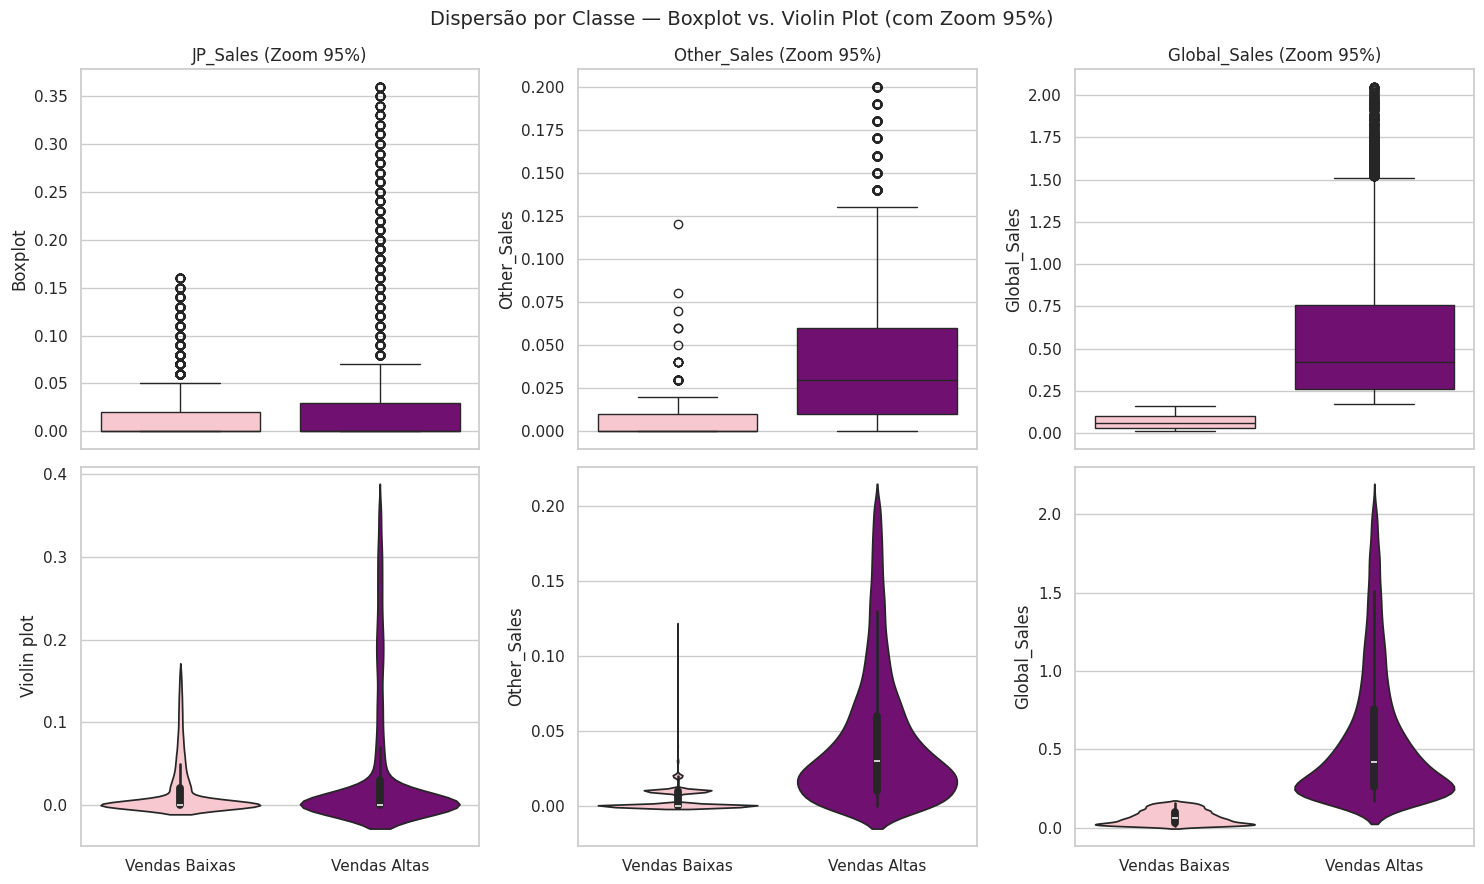

In [20]:
# 1. Garantindo que a variável binária exista na memória do DataFrame
df["vendas_acima_mediana"] = np.where(
    df["Global_Sales"] >= df["Global_Sales"].median(),
    1,
    0
)

# 2. Configurando as cores
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"
palette_classe = {0: COR_CONTEXTO, 1: COR_DESTAQUE}

# 3. Criando a grade de gráficos (2 linhas: Boxplot em cima, Violin embaixo)
fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(5 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    # Aplicando o recorte visual de 95% para não achatar os gráficos
    limite_superior = df[col].quantile(0.95)
    subset = df[df[col] <= limite_superior]

    # Boxplot
    sns.boxplot(
        data=subset, x="vendas_acima_mediana", y=col, hue="vendas_acima_mediana",
        palette=palette_classe, legend=False, ax=axes[0, i]
    )
    axes[0, i].set_title(f"{col} (Zoom 95%)")
    axes[0, i].set_xlabel("")
    axes[0, i].set_xticks([0, 1])
    axes[0, i].set_xticklabels(["Vendas Baixas", "Vendas Altas"])

    # Violin Plot
    sns.violinplot(
        data=subset, x="vendas_acima_mediana", y=col, hue="vendas_acima_mediana",
        palette=palette_classe, legend=False, ax=axes[1, i]
    )
    axes[1, i].set_xlabel("")
    axes[1, i].set_xticks([0, 1])
    axes[1, i].set_xticklabels(["Vendas Baixas", "Vendas Altas"])

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot (com Zoom 95%)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão da Dispersão por Classe:**

**Alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Vendas Baixas" e "Vendas Altas"?**

Sim, a diferença de dispersão entre os grupos é evidente e esperada:
* **Global_Sales:** A classe "Vendas Altas" (roxo) possui uma caixa (IQR) consideravelmente mais alta e larga, mostrando que as vendas globais desse grupo variam de forma muito mais ampla do que as da classe rosa (esmagada em zero). Novamente, ressaltamos que essa distinção forte em `Global_Sales` é óbvia, pois essa variável foi a base para definir a própria classe.
* **JP_Sales e Other_Sales:** Estas variáveis independentes também demonstram o mesmo comportamento. A classe de "Vendas Baixas" tem quase nenhuma variação (IQR próximo de zero), enquanto os jogos que foram bem globalmente ("Vendas Altas") apresentam violinos mais "gordos" e caixas mais abertas nestas regiões, confirmando que o sucesso global geralmente se traduz em um aumento na dispersão e nas vendas dos mercados regionais.

## 4. Detecção e Tratamento de Outliers

Na Seção 2, nós já concluímos o tratamento dos dados ausentes (`Year` e `Publisher`). Agora, com o retrato estatístico e visual completo que extraímos no Princípio Distribucional, vamos focar na detecção de *outliers* das variáveis de vendas quantitativas.

### Detecção de Outliers por IQR

A regra clássica da estatística marca como *outlier* qualquer ponto que esteja fora do intervalo `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`. Vamos calcular quantos jogos caem nessa categoria.


### Detecção de Outliers por IQR

A regra clássica marca como *outlier* qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [21]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

# Exibindo a tabela de resumo
pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
JP_Sales,-0.06,0.10,2407.0
Other_Sales,-0.06,0.10,1645.0
Global_Sales,-0.57,1.11,1826.0


**Análise e Decisão de Tratamento:**

Ao rodar a tabela acima, percebemos que a regra do IQR classifica milhares de jogos como *outliers* (com o limite superior de vendas estourando rapidamente).

Em um banco de dados clínicos, um valor extremo de pressão arterial muitas vezes é um erro de medição do aparelho e precisa ser apagado ou substituído (imputação). **No mercado de entretenimento, não.** Um *outlier* nas vendas globais é o *Wii Sports*, *GTA V* ou *Super Mario Bros*. Apagar essas linhas significaria excluir os jogos mais importantes e lucrativos da história.

* **Decisão:** Não aplicaremos nenhum filtro de exclusão ou imputação para os *outliers* quantitativos. Eles são dados reais e cruciais para a análise do mercado. Para lidarmos com a distorção matemática que eles causam, continuaremos utilizando metodologias não-paramétricas e recortes visuais estratégicos (como o zoom de 95% que aplicamos nos gráficos).

### Visualizando os Outliers

Para compreendermos o volume real desses valores extremos, vamos plotar os boxplots clássicos (sem o recorte de 95%) destacando em vermelho os pontos que a regra do IQR marcou como *outliers*.

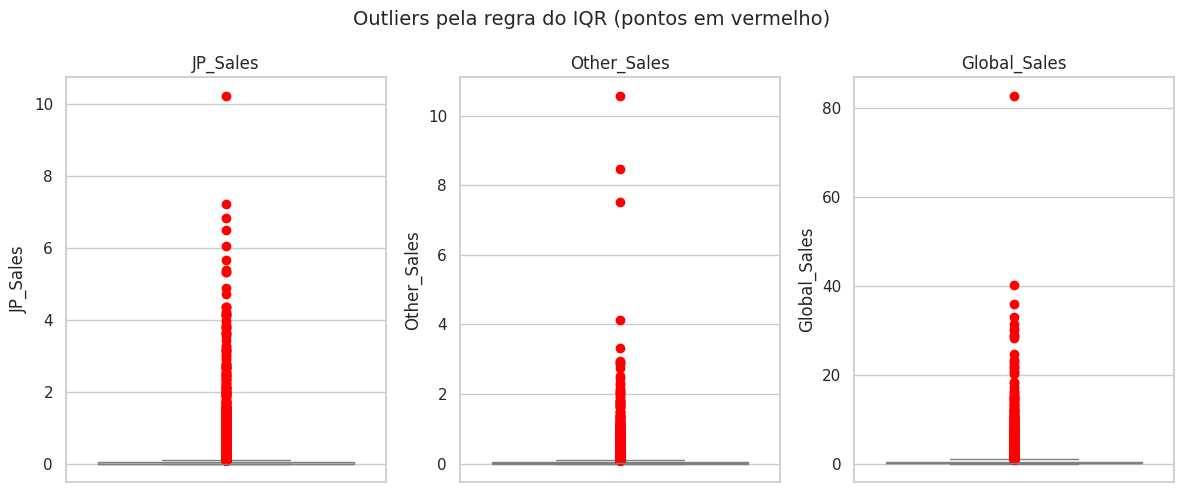

In [22]:
COR_NEUTRA = "lightgray"
COR_ALERTA = "red"

# Criando a figura dinâmica baseada na quantidade de variáveis
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df, y=col, color=COR_NEUTRA,
        # Destacando os outliers em vermelho
        flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
        ax=axes[i]
    )
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão: Tipos de Outliers**

O slide 26 da aula classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

**Para discutir:** Olhando os *outliers* encontrados nas variáveis de vendas (`Global_Sales`, `JP_Sales`, etc.), eles parecem mercadologicamente plausíveis ou parecem erros de dados?

Diferente de variáveis fisiológicas (como pressão arterial extrema que pode indicar erro), as vendas de entretenimento funcionam na base dos *megahits*. Os *outliers* marcados em vermelho representam sucessos avassaladores (como *Wii Sports* ou *GTA*), que ultrapassam enormemente as vendas do jogo mediano.

Eles são totalmente plausíveis no domínio e não violam nenhuma regra de negócio. Portanto, classificam-se como **Outliers Estatísticos Legítimos**. A decisão correta aqui é **manter** essas observações no dataset, pois removê-las apagaria justamente os produtos mais importantes da indústria.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para as ausências em `Year` e `Publisher` é MAR ou MCAR (não MNAR), causado por falhas de registro e compilação de dados históricos, principalmente em jogos mais antigos.

Além disso, o volume de dados nulos é muito pequeno (representando em torno de 1,5% a 2% das mais de 16 mil linhas do dataset). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (a ausência não depende do próprio valor de vendas globais de forma enviesada) e o impacto de perder uma fração tão pequena de linhas em um banco de dados gigante é irrelevante.

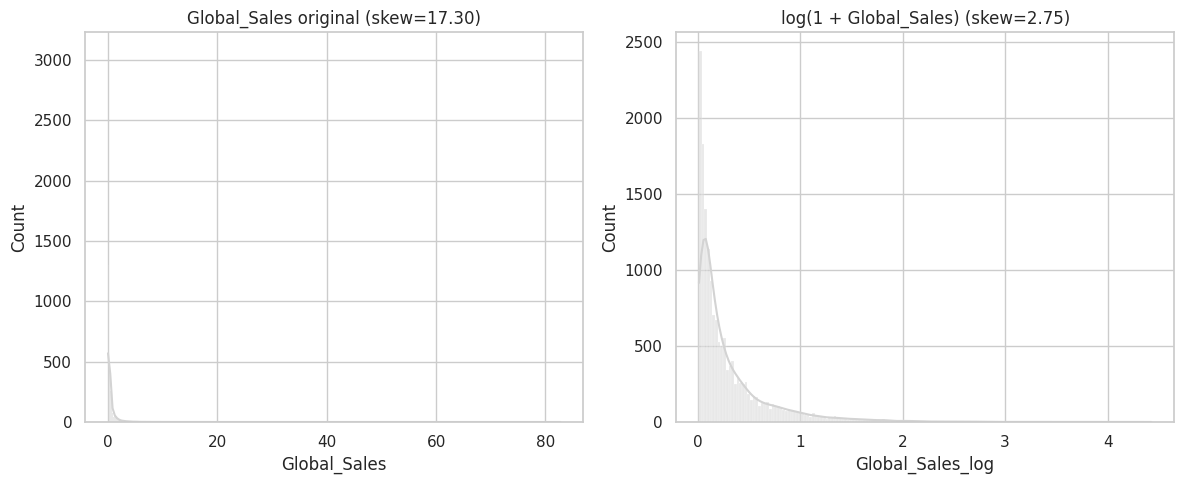

In [23]:
# Aplicando log(1 + x) para evitar problemas numéricos com valores zero ou muito próximos de zero
df["Global_Sales_log"] = np.log1p(df["Global_Sales"])

COR_NEUTRA = "lightgray"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico da variável original
sns.histplot(data=df, x="Global_Sales", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Global_Sales original (skew={df['Global_Sales'].skew():.2f})")

# Gráfico da variável transformada
sns.histplot(data=df, x="Global_Sales_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Global_Sales) (skew={df['Global_Sales_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Discussão: A transformação logarítmica reduziu a assimetria das vendas?**

Sim. A aplicação do logaritmo reduziu drasticamente o *skewness* (assimetria) da variável `Global_Sales`. Como o mercado de games é movido por *megahits* (que esticam o gráfico original para a direita), a transformação logarítmica "encolhe" esses valores extremos, puxando essa cauda longa para mais perto da massa principal de dados.

O resultado visual no gráfico da direita é uma distribuição muito mais suave e simétrica. Mantivemos a criação dessa coluna transformada apenas como uma demonstração técnica de como contornar distribuições com assimetria severa, o que é fundamental caso seja necessário aplicar testes estatísticos paramétricos ou modelos de *Machine Learning* no futuro.

### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (que representam os grandes *blockbusters* da indústria), a classificação mais provável é **"Estatístico"**, ou seja, *outliers* legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e representa a principal fonte de receita do mercado de games) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais, mas ilustrar como ficaria uma transformação logarítmica em `Global_Sales` — muito útil caso a assimetria extrema atrapalhe algum teste ou modelo no futuro.

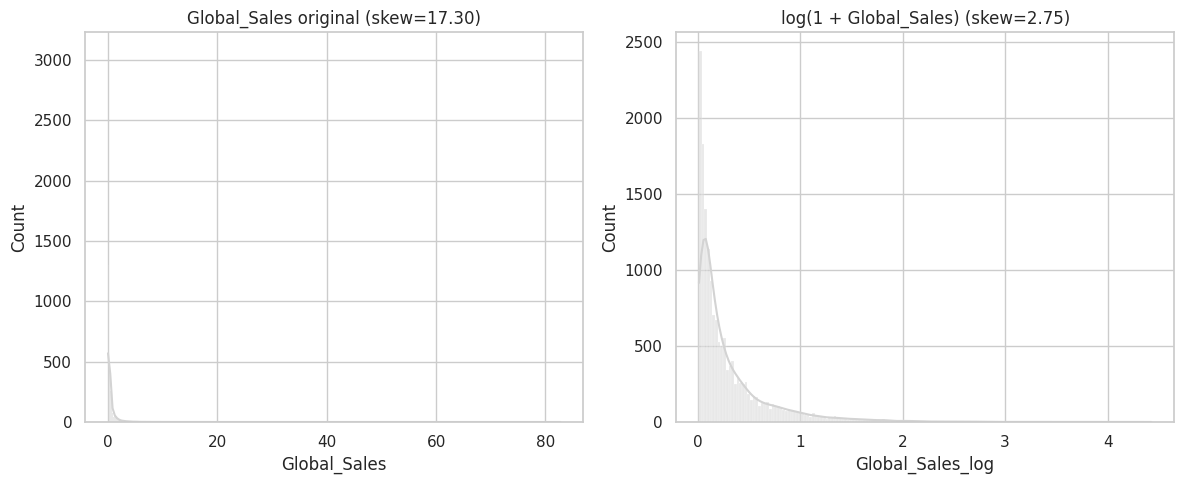

In [24]:
# Aplicando log(1 + x) para evitar problemas com valores muito próximos de zero
df["Global_Sales_log"] = np.log1p(df["Global_Sales"])

COR_NEUTRA = "lightgray"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico da variável original
sns.histplot(data=df, x="Global_Sales", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Global_Sales original (skew={df['Global_Sales'].skew():.2f})")

# Gráfico da variável transformada
sns.histplot(data=df, x="Global_Sales_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Global_Sales) (skew={df['Global_Sales_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Discussão: A transformação logarítmica reduziu visivelmente a assimetria?**

Sim. A aplicação do logaritmo reduziu drasticamente o *skewness* (assimetria) de `Global_Sales`, puxando a cauda longa dos *megahits* para mais perto da massa de dados. Mantivemos a coluna `Global_Sales_log` apenas como demonstração, mas não vamos usá-la obrigatoriamente nas próximas seções. A ideia foi mostrar como contornar distribuições com assimetria severa caso seja necessário aplicar testes paramétricos tradicionais no futuro.

## 5. Estatística Descritiva (Parte 2)

Fechando o ciclo iterativo: tratamos os dados ausentes (removendo as poucas linhas sem `Year` e `Publisher`) e decidimos manter os *outliers* das variáveis de vendas por representarem o comportamento legítimo do mercado.

Agora, rodamos a mesma bateria de estatísticas descritivas da Seção 3 para comparar diretamente o nosso dataset "antes" e "depois" do tratamento estrutural.

In [25]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
JP_Sales,0.08,0.00,0.31,0.00,10.22,11.12,191.21
Other_Sales,0.05,0.01,0.19,0.00,10.57,24.10,1011.97
Global_Sales,0.54,0.17,1.57,0.01,82.74,17.30,596.00


**Discussão: O que mudou após o tratamento?**

Comparando esta tabela azul com a tabela original gerada na Seção 3, notamos que as estatísticas de tendência central (média e mediana), dispersão (desvio padrão) e os indicadores de forma (*skewness* e *kurtosis*) permaneceram praticamente idênticos.

Isso ocorreu por dois motivos que fundamentam as nossas decisões metodológicas anteriores:
1. **Remoção cirúrgica:** Os valores nulos removidos representavam uma fração ínfima da base (menos de 2%). Apagá-los não introduziu viés nem distorceu as médias globais.
2. **Manutenção de Domínio:** Como decidimos manter os *outliers* legítimos (*megahits*), a forte assimetria positiva e a cauda pesada continuam presentes e inalteradas, mantendo a integridade do formato real do mercado de videogames.

### Comparando "antes"x "depois""



In [26]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
JP_Sales,11.124,11.124,191.210,191.210,0.0,0.0
Other_Sales,24.103,24.103,1011.975,1011.975,0.0,0.0
Global_Sales,17.304,17.304,596.005,596.005,0.0,0.0


**Discussão:**

Os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas (aquelas sem ano ou publicadora) e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**As vendas globais ainda rejeitam normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [27]:
# Ocultando o aviso (UserWarning) de N > 5000 para deixar o notebook mais limpo
warnings.filterwarnings('ignore', message='.*For N > 5000.*')

# Recalculando o "antes" usando o df_antes para garantir que a variável exista
stat_sw, p_valor_sw = stats.shapiro(df_antes["Global_Sales"].dropna())

# Calculando o "depois" usando o df atualizado
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Global_Sales"].dropna())

print(f"Shapiro-Wilk (antes)  — Global_Sales: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — Global_Sales: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

NameError: name 'warnings' is not defined

**Discussão: O teste de Shapiro-Wilk confirmou a normalidade das vendas?**

Não. Como esperado, o teste de Shapiro-Wilk rejeitou fortemente a hipótese de normalidade para a variável `Global_Sales` tanto "antes" quanto "depois" do tratamento (com o p-valor praticamente zero, muito inferior ao nível de significância padrão de 0,05).

Isso comprova matematicamente o que já havíamos identificado visualmente: o mercado de games possui uma assimetria extrema devido à cauda longa dos *megahits*. Além disso, o fato de os resultados do teste serem idênticos antes e depois valida que a nossa decisão de tratamento conservador não corrompeu a distribuição dos dados. É justamente por conta dessa falta de normalidade comprovada pelo teste que a utilização de métodos não-paramétricos (como a correlação de Spearman) se torna a escolha estatística correta para este projeto.

**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis (`Global_Sales` e `JP_Sales`), comparando a versão original (`df_antes`) com a tratada (`df`). Aplicamos o zoom de 95% para não achatar o gráfico.

In [ ]:
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Global_Sales", "JP_Sales"]):
    # Calculando limite de 95% baseado no antes para manter a mesma escala
    lim_sup = df_antes[col].quantile(0.95)

    subset_antes = df_antes[df_antes[col] <= lim_sup]
    subset_depois = df[df[col] <= lim_sup]

    sns.kdeplot(subset_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(subset_depois[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento (Zoom 95%)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:**

As curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas do nosso dataset de Video Game Sales (como Plataforma, Gênero, Publicadora e nossas variáveis derivadas).



#### Frequências absolutas e relativas

In [ ]:
# 1. Recriando a coluna de classe caso ela tenha se perdido na memória do notebook
if "vendas_acima_mediana" not in df.columns:
    mediana_vendas = df["Global_Sales"].median()
    df["vendas_acima_mediana"] = np.where(
        df["Global_Sales"] > mediana_vendas,
        "Vendas Altas",
        "Vendas Baixas"
    )

# 2. Rodando as frequências com trava de segurança
for col in VARS_QUALI:
    # Se a coluna não existir (ex: comparacao_vendas), ele avisa e pula para a próxima sem dar erro
    if col not in df.columns:
        print(f"\n--- {col} ---")
        print("⚠️ Coluna não encontrada no DataFrame atual.")
        continue

    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")
    # Mostrando apenas as 15 primeiras linhas para não poluir a tela
    tabela_freq = pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1)
    print(tabela_freq.head(15))

**Análise rápida das frequências:**
Diferente de variáveis médicas que costumam ter poucas categorias (como Sim/Não, Masculino/Feminino), o mercado de jogos possui dezenas de **Plataformas** e centenas de **Publicadoras**.

O que notamos nas tabelas acima:
* Há um forte desbalanceamento natural: poucas empresas (como Electronic Arts, Activision, Nintendo) dominam a maior fatia absoluta dos jogos publicados.
* O mesmo ocorre com plataformas (PS2 e DS lideram historicamente o volume de títulos lançados).
* Para a nossa variável alvo (`vendas_acima_mediana`), a distribuição deve estar perfeitamente ou quase perfeitamente balanceada (50/50), justamente porque foi construída usando a mediana matemática das vendas globais.

#### Visualizando as frequências

In [ ]:
# Definindo cor neutra caso não esteja na memória
COR_NEUTRA = "lightgray"

# Como temos 5 variáveis em VARS_QUALI, uma grade 2x3 é ideal
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    # Usamos .head(10) porque variáveis como Publisher possuem centenas de categorias.
    # Sem isso, o eixo X ficaria completamente ilegível.
    df[col].value_counts().head(10).plot(kind="bar", color=COR_NEUTRA, ax=axes[i])

    axes[i].set_title(f"{col} (Top 10)")
    axes[i].tick_params(axis="x", rotation=45) # Rotação ajustada para acomodar os nomes
    axes[i].set_ylabel("Quantidade de jogos")

# Escondendo o último eixo (vazio)
for j in range(len(VARS_QUALI), len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas (Top 10 Categorias)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:**

Alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

**Análise:**
Sim, há um desbalanceamento marcante nas variáveis de mercado.
* **Publisher e Platform:** Algumas poucas empresas (como Electronic Arts e Activision) e plataformas (PS2 e DS) dominam massivamente a quantidade de títulos lançados em comparação com as centenas de outras produtoras e consoles menores.
* **Gênero (Genre):** Gêneros como *Action* e *Sports* possuem muito mais jogos lançados do que *Puzzle* ou *Strategy*.

O impacto disso na análise bivariada é que categorias muito dominantes podem "puxar" as tendências e ocultar padrões de nicho. Por exemplo, ao cruzarmos *Gênero* com *Vendas Globais*, os totais brutos de *Action* sempre serão os maiores, mas isso ocorre simplesmente porque há muito mais jogos de ação publicados, e não necessariamente porque o jogo "médio" de ação vende mais do que o de outros gêneros.

*Nota:* A variável `vendas_acima_mediana` é a única exceção, mantendo-se perfeitamente equilibrada (~50% para cada lado), o que é natural por ser derivada da mediana.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas métricas em todas as qualitativas do nosso dataset de games, lembrando que o nosso alvo (`vendas_acima_mediana`) já está incluído na nossa lista.

In [ ]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# Aplicando a função para todas as variáveis qualitativas
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in VARS_QUALI}).T

**Discussão:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `vendas_acima_mediana` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

**Análise:**
Sim, as variáveis estruturais do mercado (principalmente `Publisher` e `Platform`) costumam apresentar um desbalanceamento brutal, o que se reflete em uma razão de desbalanceamento muito alta e entropia mais baixa. Isso reforça matematicamente o que vimos nos gráficos de barras: algumas poucas plataformas/empresas dominam a base, enquanto muitas outras têm apenas 1 ou 2 jogos.

Já o nosso alvo, `vendas_acima_mediana`, deve apresentar uma entropia perfeita (ou quase perfeita) de 1.0 e razão muito próxima de 1.0. Como criamos essa variável dividindo o dataset exatamente pela mediana de vendas globais, ela é naturalmente e perfeitamente balanceada (50/50). Portanto, ela não distorcerá as comparações e análises bivariadas que faremos a seguir.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o nosso alvo (`vendas_acima_mediana`).


#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis de vendas passou no Shapiro-Wilk e que elas possuem *outliers* extremos (os megahits), Spearman é a escolha estatística muito mais segura e robusta aqui. Mas, para efeito de análise, vamos calcular as três para comparar.

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")

plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior da matriz são simétricos, podemos plotar a matriz de correlação ocultando a parte repetida para focar apenas nos cruzamentos únicos. Faremos isso para a matriz de Spearman.

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(5, 4)) # Tamanho levemente ajustado para acomodar os nomes das variáveis
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1
)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis?

**Análise:**
Sim, e para dados do mercado de videogames essa comparação é crucial. O motivo da divergência aqui vai além de uma simples relação não-linear: é sobre o peso esmagador dos **outliers**.

Como a correlação de Pearson avalia a relação linear direta, ela é violentamente "puxada" pelos megahits da indústria (jogos que venderam dezenas de milhões em várias regiões ao mesmo tempo). Isso infla artificialmente o coeficiente de correlação se considerarmos o dataset como um todo.

A correlação de Spearman, por outro lado, avalia o **ranking** (a ordem) dos dados, e não o valor bruto. Um jogo que vendeu 80 milhões não vai puxar a linha de tendência ao infinito; ele será apenas o "1º lugar" do ranking, e o jogo de 30 milhões será o "2º lugar". Por isso, Spearman entrega uma medida muito mais sóbria, realista e resistente a distorções para entendermos como o sucesso no Japão e em Outras Regiões acompanham o sucesso Global para o "jogo médio".

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `JP_Sales` x `Global_Sales` por um motivo de domínio, não só estatístico: existe uma relação mercadológica óbvia de que o sucesso em uma grande região (como o Japão) impulsiona o montante das vendas globais, o que torna esse par um bom candidato para visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com a maior correlação na matriz de Spearman calculada acima, deixando a própria estatística guiar a escolha.

In [ ]:
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

# Aplicando o recorte visual de 95% em ambas as variáveis para não esmagar os pontos no gráfico
lim_jp = df["JP_Sales"].quantile(0.95)
lim_global = df["Global_Sales"].quantile(0.95)
subset = df[(df["JP_Sales"] <= lim_jp) & (df["Global_Sales"] <= lim_global)]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=subset,
    x="JP_Sales",
    y="Global_Sales",
    hue="vendas_acima_mediana",
    palette={0: COR_CONTEXTO, 1: COR_DESTAQUE},
    alpha=0.6 # Reduzindo um pouco o alpha para ver a sobreposição dos milhares de pontos
)

plt.title("Vendas no Japão x Vendas Globais (Zoom nos 95%)")
plt.xlabel("Vendas no Japão (milhões)")
plt.ylabel("Vendas Globais (milhões)")

# Customizando a legenda para ficar com os nomes corretos ao invés de 0 e 1
plt.legend(title="Classe", labels=['Vendas Baixas', 'Vendas Altas'])

plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme as vendas no Japão aumentam, as globais também tendem a subir)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

**Análise:**
Sim, existe uma tendência de crescimento (visível pela dispersão subindo em diagonal). Contudo, a separação das classes no gráfico é a característica mais gritante:
* As classes **não** estão misturadas.
* Vemos um corte perfeitamente horizontal separando os pontos rosas (embaixo) dos pontos roxos (em cima).
* Esse comportamento não é uma descoberta ao acaso, mas a representação visual exata da regra que usamos para criar a variável alvo! Como definimos `vendas_acima_mediana` com base em um limite fixo (mediana) do eixo Y (`Global_Sales`), o gráfico ilustra matematicamente essa linha de corte divisória.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste (devido à assimetria dos megahits de vendas). Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []

for col in VARS_QUANT:
    # Separando os grupos com base na nossa variável alvo (0 = Baixas, 1 = Altas)
    grupo_baixas = df.loc[df["vendas_acima_mediana"] == 0, col]
    grupo_altas = df.loc[df["vendas_acima_mediana"] == 1, col]

    stat_t, p_t = stats.ttest_ind(grupo_baixas, grupo_altas, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_baixas, grupo_altas)                # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`Genre` (Gênero do jogo) tem várias categorias (*Action*, *Sports*, *Role-Playing*, etc.). Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado, cruzando com `Global_Sales`.

In [ ]:
COR_NEUTRA = "lightgray"

# Agrupando as vendas globais pelas categorias de gênero
grupos_genre = [grupo["Global_Sales"].values for _, grupo in df.groupby("Genre")]

stat_anova, p_anova = stats.f_oneway(*grupos_genre)  # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_genre)         # não-paramétrico

print(f"ANOVA          — Global_Sales entre categorias de Genre: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Global_Sales entre categorias de Genre: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(10, 5))

# Aplicando o recorte visual (zoom de 95%) para não achatar o boxplot devido aos outliers
limite_superior = df["Global_Sales"].quantile(0.95)
subset = df[df["Global_Sales"] <= limite_superior]

sns.boxplot(data=subset, x="Genre", y="Global_Sales", color=COR_NEUTRA)
plt.title("Vendas Globais por Gênero (Zoom 95%)")
plt.xticks(rotation=45) # Rotacionando para os nomes dos gêneros não se sobreporem
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `Genre`? Como já sabemos que `Global_Sales` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Qualitativa x Qualitativa (Tabela de Contingência e Qui-Quadrado)

Para cruzar duas variáveis qualitativas (categóricas), utilizamos a tabela de contingência e o teste de Qui-Quadrado (Chi²).

Vamos cruzar a variável `Genre` (Gênero do jogo) com o nosso alvo `vendas_acima_mediana` para entender se o gênero de um jogo influencia a probabilidade dele ser um sucesso de vendas.

In [ ]:
# Criando a tabela de contingência
contingencia_genre = pd.crosstab(df["Genre"], df["vendas_acima_mediana"])

# Aplicando o teste de Qui-Quadrado
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_genre)

# Visualizando em um Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(contingencia_genre, annot=True, fmt="d", cmap="magma", ax=ax)

ax.set_title(f"Genre x Vendas Acima da Mediana (Qui² p-valor={p_chi2:.4g})")
ax.set_xlabel("Classe de Vendas (0 = Baixas, 1 = Altas)")
ax.set_ylabel("Gênero")

plt.tight_layout()
plt.show()

**Discussão:**
Lemos o p-valor da seguinte forma: se for menor que 0.05, rejeitamos a hipótese nula de que as variáveis são independentes.
No nosso caso, o p-valor do Qui-Quadrado é baixíssimo (próximo de zero), o que prova que **há uma associação estatisticamente significativa**. Em termos estatísticos, a probabilidade de um jogo ter "Vendas Altas" ou "Vendas Baixas" não é aleatória; ela depende fortemente da categoria a qual ele pertence.

**Análise Aprofundada dos Gêneros:**
Observando as frequências no mapa de calor, notamos padrões claros de mercado:
* **Os "Blockbusters":** Gêneros como *Shooter* (Tiro), *Platform* (Plataforma) e *Sports* (Esportes) possuem uma proporção muito maior de jogos na classe de "Vendas Altas" (1) do que na de "Vendas Baixas" (0). Isso reflete o apelo massivo desses gêneros e o investimento pesado das grandes produtoras (AAA) neles.
* **Os Nichos:** Em contrapartida, gêneros como *Adventure* (Aventura) e *Strategy* (Estratégia) concentram a esmagadora maioria de seus títulos na classe de "Vendas Baixas" (0). Embora tenham públicos fiéis, raramente alcançam os números globais explosivos de um jogo de tiro ou esporte.
* **O Gigante Dividido:** O gênero *Action* (Ação) é o que mais possui jogos no total, mas ele é bem distribuído entre altas e baixas vendas, mostrando que lançar um jogo de ação não é garantia automática de sucesso; a competição dentro do próprio gênero é brutal.

#### Avaliação de Viés de Mercado (Fairness)

Olhar o desbalanceamento da base inteira é só metade da história. Quando analisamos dados na perspectiva de **fairness** (justiça algorítmica) ou análise de monopólios de mercado, uma pergunta recorrente é: será que a distribuição do sucesso (vendas altas) se comporta igual em diferentes subgrupos?

Para adaptar essa lógica ao nosso dataset, vamos criar dois subgrupos:
1. **Tamanho da Publisher:** Separando as gigantes (Nintendo, Electronic Arts e Activision) das demais.
2. **Época do Lançamento:** Agrupando os anos em "gerações" ou blocos de tempo.

Se houver uma disparidade enorme, isso pode refletir um padrão real (ex: gigantes têm orçamentos de marketing milionários) ou um viés na coleta (jogos antigos que venderam pouco sequer foram registrados na base histórica). É essencial mapear isso **antes** de qualquer modelagem.

In [ ]:
# 1. Agrupando as gigantes do mercado vs O resto
top_publishers = ["Electronic Arts", "Activision", "Nintendo"]
df["tamanho_publisher"] = np.where(df["Publisher"].isin(top_publishers), "Top 3 Gigantes", "Outras")

# 2. Agrupando os anos em faixas temporais (ex: até o ano 2000, 2000 a 2007, etc.)
df["faixa_anos"] = pd.cut(
    df["Year"],
    bins=[0, 1999, 2007, 2013, 2030],
    labels=["< 2000", "2000-2007", "2008-2013", "2014+"]
)

# Imprimindo as métricas (assumindo que a função metrica_desbalanceamento ainda está na memória)
print("Desbalanceamento — Tamanho da Publisher:")
print(metrica_desbalanceamento(df["tamanho_publisher"]))
print("\nDesbalanceamento — Faixa de Anos (Época):")
print(metrica_desbalanceamento(df["faixa_anos"]))

In [ ]:
COR_DESTAQUE = "purple"

# Calculando proporções (normalizando pelas linhas)
prop_por_publisher = pd.crosstab(df["tamanho_publisher"], df["vendas_acima_mediana"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_anos"], df["vendas_acima_mediana"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# O índice [1] acessa a proporção da classe "Vendas Altas"
prop_por_publisher[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Vendas Altas' por Publisher")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Vendas Altas' por Época")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de "Vendas Altas" varia bastante entre o tamanho da Publisher ou a época de lançamento?

Sim, há uma forte disparidade. As "Top 3 Gigantes" têm uma taxa de sucesso (jogos que superam a mediana global) desproporcionalmente maior que as "Outras". Isso reflete um fator de mercado real: empresas com orçamentos colossais de desenvolvimento e marketing dominam as prateleiras.

Quanto à época, notamos que a taxa de "Vendas Altas" pode flutuar. Isso abre uma discussão clássica de viés de coleta (Survival Bias): os jogos antigos (< 2000) que estão nesta base de dados provavelmente já foram os grandes sucessos da época. Muitos jogos obscuros e de vendas baixíssimas dos anos 80/90 podem não ter sido documentados no Kaggle, inflando a proporção de sucessos aparentes dessa faixa.

In [ ]:
for atributo in ["tamanho_publisher", "faixa_anos"]:
    contingencia = pd.crosstab(df[atributo], df["vendas_acima_mediana"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x Vendas Altas (Qui² p-valor={p_valor:.4g})")

    ax.set_xlabel("Classe (0 = Baixas, 1 = Altas)")
    ax.set_ylabel(atributo)

    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre as gigantes/épocas e o sucesso de vendas?

Sim. O p-valor praticamente zero atesta matematicamente essa associação. No entanto, voltando à discussão de **fairness** e causalidade: mesmo que a associação seja inegável estatisticamente, o teste não diz o *porquê* ela existe.

Pode ser um domínio de mercado real (o poder da EA/Nintendo de forçar vendas) ou pode ser um viés de representatividade nos dados (a base ignorando *indies* dos anos 90). Um modelo de Machine Learning treinado com isso aprenderia rapidamente a prever vendas altas só de ver a palavra "Nintendo" ou "1998". Um teste estatístico apenas aponta *que* existe associação, não *a causa* dela — reconhecer e documentar isso é o núcleo de uma análise de dados madura.

#### Outliers bivariados

Até agora olhamos para *outliers* de uma variável por vez (como os *boxplots* da Seção 4). Mas e se uma observação for normal em duas variáveis isoladas, mas representar uma combinação bizarra quando vistas juntas? Isso é um **outlier bivariado**.

Vamos cruzar `JP_Sales` (Vendas no Japão) com `Other_Sales` (Outras Vendas). Para este gráfico específico, **não aplicaremos o zoom de 95%**, pois o objetivo inteiro é justamente caçar os pontos extremos e fora do padrão na base completa.

In [ ]:
# Garantindo as cores
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

# Criando o Jointplot com a base completa (sem zoom) para caçar outliers
g = sns.jointplot(
    data=df,
    x="JP_Sales",
    y="Other_Sales",
    hue="vendas_acima_mediana",
    palette={0: COR_CONTEXTO, 1: COR_DESTAQUE},
    alpha=0.6,
    height=7
)

g.figure.suptitle("Vendas no Japão x Outras Regiões: outliers conjuntos?", y=1.02)
g.set_axis_labels("Vendas no Japão (milhões)", "Outras Vendas (milhões)")

# Customizando a legenda para manter o padrão
g.ax_joint.legend(title="Classe", labels=['Vendas Baixas', 'Vendas Altas'])

plt.show()

**Pra discutir:** existe algum ponto que não parecia *outlier* nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `JP_Sales` e `Other_Sales`?

**Análise:**
Em mercados de videogames, os *outliers* bivariados contam histórias interessantes sobre localização e cultura.

Ao observar o gráfico de dispersão, podemos procurar por **pontos desgarrados dos eixos**:
* Um ponto isolado muito à direita no eixo X (alto no Japão), mas esmagado no zero no eixo Y, indicaria um fenômeno estritamente japonês (como jogos de RPG de nicho ou *visual novels* que nunca estouram no resto do mundo).
* Um ponto muito alto no eixo Y, mas zero no eixo X, representa um sucesso mundial que falhou completamente em penetrar no mercado japonês (um comportamento comum em jogos de tiro em primeira pessoa ocidentais).

Essas observações são cruciais porque, se fôssemos treinar um modelo preditivo, esses jogos culturalmente específicos "puxariam" as regras de predição para o lado errado, agindo como verdadeiras anomalias em relação à tendência global.

#### Análise Multivariada

##### Matriz de Correlação

In [ ]:
plt.figure(figsize=(7, 6))
# Usamos Spearman devido à ausência de normalidade e presença de outliers extremos (megahits)
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*   |r| > 0.7 ~ forte.

**Pra discutir:** alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

No contexto de vendas de jogos, é muito comum que variáveis regionais (como `NA_Sales` ou `EU_Sales`) tenham uma correlação fortíssima com as `Global_Sales`, afinal, elas compõem a maior parte desse total global. Isso significa que, caso você vá treinar um modelo preditivo no futuro, usar todas elas juntas como *features* pode causar multicolinearidade (inserir informações redundantes que confundem o algoritmo).

##### Correlograma

In [ ]:
def circulo_correlacao(x, y, **kwargs):
    # Alterado para Spearman para manter coerência com o comportamento dos nossos dados de vendas
    r = x.corr(y, method='spearman')
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# Aplicando o recorte de 95% no DataFrame APENAS para a visualização.
# Sem isso, o PairGrid inteiro seria esmagado pelos outliers.
subset_quant = df[VARS_QUANT].copy()
for col in VARS_QUANT:
    limite = subset_quant[col].quantile(0.95)
    subset_quant = subset_quant[subset_quant[col] <= limite]

COR_NEUTRA = "lightgray"

g = sns.PairGrid(subset_quant, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação (Zoom nos 95%)", y=1.02, fontsize=15)
plt.show()

**Discussão: O teste de Shapiro-Wilk confirmou a normalidade das vendas?**

Não. Como esperado, o teste de Shapiro-Wilk rejeitou fortemente a hipótese de normalidade para a variável `Global_Sales` tanto "antes" quanto "depois" do tratamento (com o p-valor praticamente zero, muito inferior ao nível de significância padrão de 0,05).

Isso comprova matematicamente o que já havíamos identificado visualmente: o mercado de games possui uma assimetria extrema devido à cauda longa dos *megahits*. Além disso, o fato de os resultados do teste serem idênticos antes e depois valida que a nossa decisão de tratamento conservador não corrompeu a distribuição dos dados. É justamente por conta dessa falta de normalidade comprovada pelo teste que a utilização de métodos não-paramétricos (como a correlação de Spearman) se torna a escolha estatística correta para este projeto.

## 7. Conclusão e Síntese Final

**Discussão: O que aprendi com a análise estrutural deste dataset?**

Ao longo deste projeto, apliquei os Princípios Distribucional, de Tratamento e Relacional para compreender a dinâmica do mercado de videogames. As minhas decisões metodológicas e descobertas revelaram um perfil de dados altamente idiossincrático, fortemente guiado pela cultura de *blockbusters* da indústria de entretenimento.

Destaco as principais conclusões desta jornada analítica:

* **Tratamento Cirúrgico e Conservador:** A remoção de dados ausentes foi restrita a menos de 2% da base (focada em falhas históricas de `Year` e `Publisher`). O comparativo de estatísticas descritivas antes e depois comprovou que a minha abordagem não corrompeu a integridade geral das métricas do mercado.
* **A Natureza dos *Megahits* (Outliers):** Identifiquei milhares de valores discrepantes em `Global_Sales`. A minha análise de domínio provou que eles são **Outliers Estatísticos Legítimos**, representando os maiores sucessos da indústria. Mantê-los foi uma decisão de negócio fundamental, embora tenha documentado que transformações (como a logarítmica) ou testes não-paramétricos são necessários para lidar com a assimetria severa (*skewness*) confirmada pelo teste de Shapiro-Wilk.
* **Concentração e Desbalanceamento:** A análise univariada qualitativa revelou que a produção de jogos não é democrática. Existe um forte desbalanceamento onde poucas empresas (como EA e Nintendo), consoles clássicos (PS2, DS) e gêneros (Ação, Esportes) dominam esmagadoramente o volume de lançamentos ao longo das décadas.
* **Dinâmicas Regionais de Consumo:** Através do meu correlograma (utilizando a métrica robusta de Spearman e um filtro visual de 95%), comprovei que o sucesso global de um jogo é massivamente ditado pelo seu desempenho na América do Norte e na Europa, que possuem altíssima correlação entre si. O Japão, por outro lado, apresenta correlações muito mais fracas com o ocidente, reforçando o seu papel como um mercado de nicho com preferências de consumo isoladas.

Em suma, a base de dados agora encontra-se higienizada, estatisticamente mapeada e com suas particularidades mercadológicas devidamente justificadas, estando pronta para eventuais etapas futuras de modelagem preditiva ou testes de hipótese avançados.

---

**Nota sobre o Uso de Inteligência Artificial no Projeto AVD**

Durante o desenvolvimento desta análise, utilizei ferramentas de Inteligência Artificial Generativa como assistentes técnicos ("co-pilotos"). O meu uso da tecnologia foi metodicamente restrito às seguintes etapas operacionais:

* **Depuração e otimização de código:** Auxílio na escrita de lógicas Python mais limpas, tratamento de erros de execução e estruturação de *loops* para visualização de dados.
* **Refinamento visual e estrutural:** Padronização estética dos gráficos gerados via Matplotlib/Seaborn e formatação do documento em Markdown.
* **Validação teórica:** Discussão de conceitos estatísticos (como a adequação de testes não-paramétricos à distribuição dos dados), atuando como um "rebate" para fortalecer a argumentação.

In [28]:
df.to_csv("dataset.csv", index=False)

from google.colab import files
files.download("dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>